# Waves Survey-mode data

Similar to the magnetometer data, we can load and plot data from the Waves instrument.  Currently, `junopy` only supports loading 
Waves Survey data.  Burst-mode data will be implemented at a future time.

In [10]:
import datetime as dt
import numpy as np
from matplotlib import pyplot as plt

from junopy import config
from junopy import waves
from junopy import utils

config.ConfigVars.set_root(".junodata")   # <--- Change as needed.

Similar to `mag`, `waves` also has a convenience method called `get_waves_data_for_date`.

In [4]:
start = dt.datetime(2020, 1, 1, 2)
stop = dt.datetime(2020, 1, 1, 23)

electric_spectra, magnetic_spectra = waves.get_waves_data_for_date(date=start.date()) 

And the data can be plotted using the `.plot()` method of the `WavesSurveyData` object.

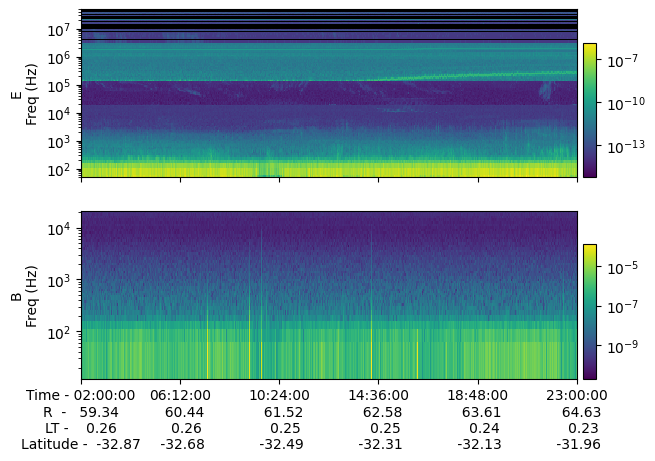

In [11]:
fig, axs = plt.subplots(2, 1, sharex=True)

electric_spectra.plot(ax=axs[0])
magnetic_spectra.plot(ax=axs[1])

tick_times, tick_strings = utils.plot.find_ticks_between(start, stop, nticks=6)

axs[0].set_ylim([50, 5e7])

for a in axs:
    a.set_facecolor('k')
    a.set_xlim([tick_times[0], tick_times[-1]])
    a.xaxis.set_ticks(tick_times, tick_strings)
    a.label_outer()

plt.show()